In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
FILE = "Water Quality.csv"  # Change to full path if required.

def locate_csv(filename):
    p = Path(filename)
    if p.is_file(): return p.resolve()
    for root in [Path.cwd(), Path.home()/"Desktop", Path.home()/"Downloads", Path.home()/"Documents"]:
        if root.exists():
            try:
                for item in root.rglob("*"):
                    if item.is_file() and item.name.lower() == filename.lower(): return item.resolve()
            except (OSError, PermissionError): pass
    try:
        import tkinter as tk
        from tkinter import filedialog
        w=tk.Tk(); w.withdraw(); w.attributes("-topmost", True)
        chosen=filedialog.askopenfilename(title="Select Water Quality.csv",filetypes=[("CSV","*.csv")])
        w.destroy()
        return Path(chosen) if chosen else None
    except Exception: return None

csv_path=locate_csv(FILE)
if csv_path is None: raise FileNotFoundError("Put Water Quality.csv beside the notebook or set FILE to its full path.")
df=pd.read_csv(csv_path, low_memory=False); df.columns=df.columns.str.strip()
required={"MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"}
if not required.issubset(df.columns): raise ValueError(f"Missing columns: {sorted(required-set(df.columns))}")
df["ActivityStartDate"]=pd.to_datetime(df["ActivityStartDate"], errors="coerce")
df["ResultValue"]=pd.to_numeric(df["ResultValue"], errors="coerce")
df=df.dropna(subset=["MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"]).copy()
for c in ["MonitoringLocationID","CharacteristicName"]: df[c]=df[c].astype(str).str.strip()
if "ResultUnit" not in df: df["ResultUnit"]="UNSPECIFIED"
df["ResultUnit"]=df["ResultUnit"].fillna("UNSPECIFIED").astype(str).str.strip()
print("Loaded:", csv_path, "| rows:",len(df),"| locations:",df.MonitoringLocationID.nunique(),"| parameters:",df.CharacteristicName.nunique())

Loaded: C:\Users\YASH\Desktop\water\Water Quality.csv | rows: 229916 | locations: 58 | parameters: 83


In [2]:
df["YearMonth"]=df.ActivityStartDate.dt.to_period("M")
monthly=(df.groupby(["MonitoringLocationID","CharacteristicName","ResultUnit","YearMonth"])["ResultValue"].median().reset_index())
monthly["Month"]=monthly.YearMonth.dt.to_timestamp()
coverage=(monthly.groupby(["MonitoringLocationID","CharacteristicName","ResultUnit"]).size().rename("MonthlyRecords").reset_index().sort_values("MonthlyRecords",ascending=False))
display(coverage.head(20))

,MonitoringLocationID,CharacteristicName,ResultUnit,MonthlyRecords
907,NS01ED0005,pH,UNSPECIFIED,272
887,NS01ED0005,Specific conductance,uS/cm,272
838,NS01ED0005,Aluminum,ug/L,272
871,NS01ED0005,Manganese,ug/L,271
896,NS01ED0005,"Total Nitrogen, mixed forms",mg/L,271
870,NS01ED0005,Magnesium,mg/L,271
878,NS01ED0005,Organic carbon,mg/L,271
851,NS01ED0005,Chloride,mg/L,271
886,NS01ED0005,Sodium,mg/L,271
889,NS01ED0005,Sulfate,mg/L,271


In [3]:
LOCATION_ID=None  # Optional: enter exact MonitoringLocationID
PARAMETER=None    # Optional: enter exact CharacteristicName
UNIT=None         # Optional: enter exact ResultUnit
MIN_MONTHS=30
eligible=coverage[coverage.MonthlyRecords>=MIN_MONTHS]
if eligible.empty: raise ValueError(f"No series has {MIN_MONTHS} monthly records; review coverage and adjust only if justified.")
if LOCATION_ID is None or PARAMETER is None:
    chosen=eligible.iloc[0]
    LOCATION_ID=str(chosen.MonitoringLocationID); PARAMETER=str(chosen.CharacteristicName)
    if UNIT is None: UNIT=str(chosen.ResultUnit)
elif UNIT is None:
    matches=coverage[(coverage.MonitoringLocationID==LOCATION_ID)&(coverage.CharacteristicName==PARAMETER)]
    if matches.empty: raise ValueError("Selected series not found.")
    UNIT=str(matches.iloc[0].ResultUnit)
selected=monthly[(monthly.MonitoringLocationID==LOCATION_ID)&(monthly.CharacteristicName==PARAMETER)&(monthly.ResultUnit==UNIT)].sort_values("Month")
series=selected.set_index("Month")["ResultValue"].asfreq("MS").astype(float)
print("Location:",LOCATION_ID,"| Parameter:",PARAMETER,"| Unit:",UNIT)
print("Calendar months:",len(series),"| observed:",int(series.notna().sum()))
display(selected.head())

Location: NS01ED0005 | Parameter: pH | Unit: UNSPECIFIED
Calendar months: 287 | observed: 272


,MonitoringLocationID,CharacteristicName,ResultUnit,YearMonth,ResultValue,Month
46722,NS01ED0005,pH,UNSPECIFIED,2000-01,4.700,2000-01-01
46723,NS01ED0005,pH,UNSPECIFIED,2000-02,4.630,2000-02-01
46724,NS01ED0005,pH,UNSPECIFIED,2000-03,4.805,2000-03-01
46725,NS01ED0005,pH,UNSPECIFIED,2000-04,4.745,2000-04-01
46726,NS01ED0005,pH,UNSPECIFIED,2000-05,4.890,2000-05-01


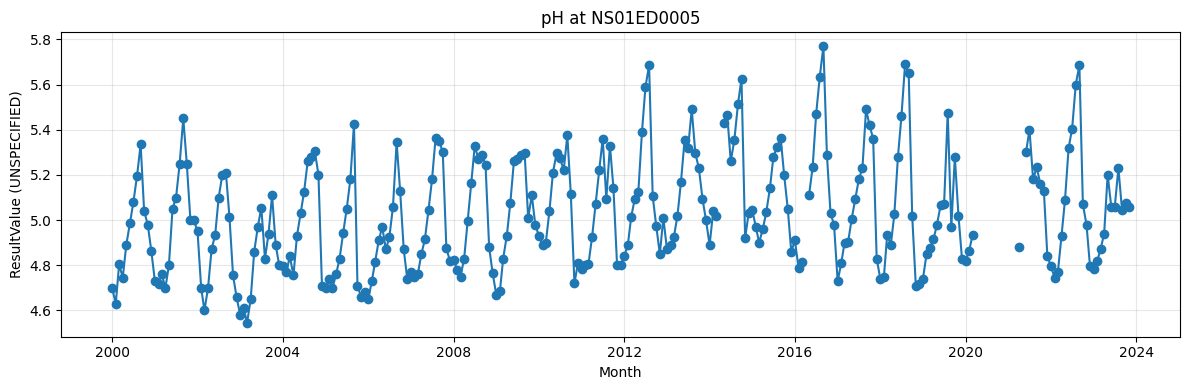

Usable months: 287 | internal missing months interpolated: 15


In [4]:
plt.figure(figsize=(12,4)); plt.plot(series.index,series.values,marker="o")
plt.title(f"{PARAMETER} at {LOCATION_ID}"); plt.xlabel("Month"); plt.ylabel(f"ResultValue ({UNIT})")
plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()
series_model=series.interpolate(method="time",limit_area="inside").dropna()
if len(series_model)<MIN_MONTHS: raise ValueError(f"Only {len(series_model)} usable months remain.")
print("Usable months:",len(series_model),"| internal missing months interpolated:",int(series_model.index.difference(series.dropna().index).size))

In [5]:
from statsmodels.tsa.stattools import adfuller
adf_stat,adf_p,_,_,critical,_=adfuller(series_model,autolag="AIC")
print(f"ADF statistic={adf_stat:.4f}; p-value={adf_p:.4f}; critical values={critical}")
print("Reject unit-root null at 5%." if adf_p<.05 else "Stationarity is not established at 5%; interpret AR/MA/ARMA cautiously.")

ADF statistic=-2.3168; p-value=0.1666; critical values={'1%': np.float64(-3.454355055831705), '5%': np.float64(-2.8721080938842976), '10%': np.float64(-2.572401325619835)}
Stationarity is not established at 5%; interpret AR/MA/ARMA cautiously.


C:\Users\YASH\AppData\Local\Temp\ipykernel_16720\2947012396.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat,adf_p,_,_,critical,_=adfuller(series_model,autolag="AIC")


In [6]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
test_n=max(3,int(round(len(series_model)*.2)))
train,test=series_model.iloc[:-test_n],series_model.iloc[-test_n:]
MAX_ORDER=3
fits={}; rows=[]
for p in range(MAX_ORDER+1):
    for q in range(MAX_ORDER+1):
        if p==0 and q==0: continue
        try:
            fit=ARIMA(train,order=(p,0,q),enforce_stationarity=False,enforce_invertibility=False).fit()
            kind="AR" if q==0 else ("MA" if p==0 else "ARMA")
            fits[(p,q)]=fit
            rows.append({"Model":kind,"p":p,"d":0,"q":q,"AIC":fit.aic,"BIC":fit.bic})
        except Exception as e: print("Skipped", (p,0,q), str(e)[:100])
aicbic=pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
if aicbic.empty: raise RuntimeError("No model fit successfully.")
display(aicbic)

c:\Users\YASH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\YASH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\YASH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Model,p,d,q,AIC,BIC
0,ARMA,3,0,2,-268.651994,-244.677344
1,ARMA,3,0,3,-265.062958,-237.698678
2,ARMA,2,0,3,-248.856921,-224.913176
3,ARMA,2,0,1,-218.943548,-201.796820
4,ARMA,2,0,2,-216.492586,-195.942886
5,ARMA,3,0,1,-215.919048,-195.369348
6,AR,3,0,0,-210.237249,-193.112498
7,AR,2,0,0,-205.007179,-191.289797
8,ARMA,1,0,2,-196.696044,-179.571294
9,ARMA,1,0,3,-195.666131,-175.142921


In [7]:
eval_rows=[]; preds={}
for (p,q),fit in fits.items():
    try:
        pred=np.asarray(fit.forecast(steps=len(test)))
        row=aicbic[(aicbic.p==p)&(aicbic.q==q)].iloc[0]
        eval_rows.append({"Model":row.Model,"p":p,"d":0,"q":q,"AIC_train":row.AIC,"BIC_train":row.BIC,
                          "MAE_test":mean_absolute_error(test,pred),"RMSE_test":mean_squared_error(test,pred)**.5})
        preds[(p,q)]=pred
    except Exception as e: print("Forecast failed", (p,q), str(e)[:100])
evaluation=pd.DataFrame(eval_rows).sort_values("RMSE_test").reset_index(drop=True)
display(evaluation)
best=evaluation.iloc[0]; best_order=(int(best.p),0,int(best.q))
print("Lowest holdout RMSE:",best.Model,best_order)

,Model,p,d,q,AIC_train,BIC_train,MAE_test,RMSE_test
0,ARMA,2,0,3,-248.856921,-224.913176,0.119620,0.161587
1,ARMA,3,0,3,-265.062958,-237.698678,0.132918,0.174362
2,ARMA,3,0,2,-268.651994,-244.677344,0.143577,0.186792
3,ARMA,2,0,2,-216.492586,-195.942886,0.162507,0.202992
4,ARMA,3,0,1,-215.919048,-195.369348,0.161639,0.203010
5,ARMA,2,0,1,-218.943548,-201.796820,0.161105,0.203071
6,AR,3,0,0,-210.237249,-193.112498,0.161595,0.205541
7,AR,2,0,0,-205.007179,-191.289797,0.160412,0.205587
8,MA,0,0,3,-190.586956,-173.484281,0.159619,0.205630
9,ARMA,1,0,3,-195.666131,-175.142921,0.159963,0.205729


Lowest holdout RMSE: ARMA (2, 0, 3)


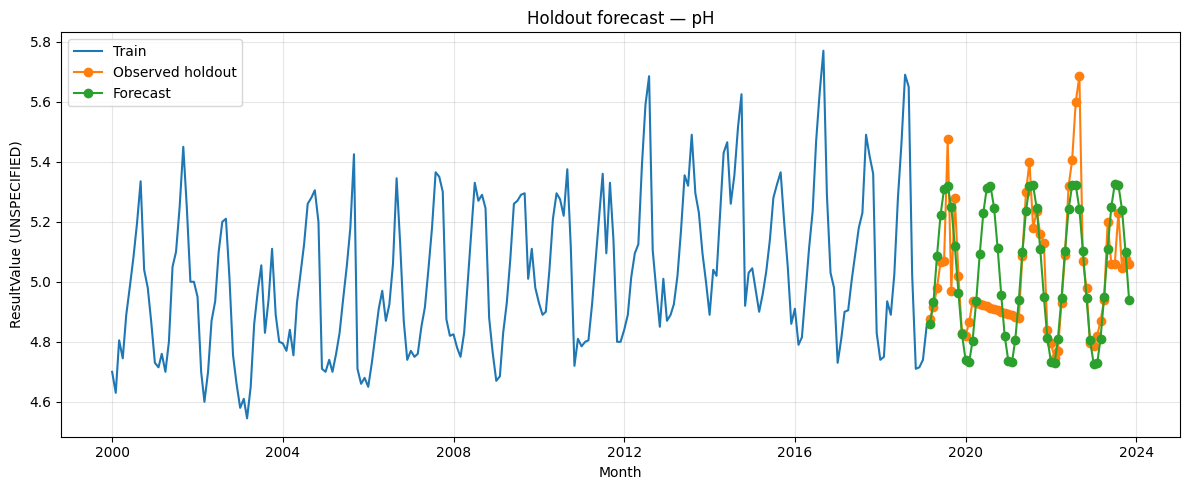

Outputs saved to: C:\Users\YASH\Desktop\water\task1_ar_ma_arma_outputs


,Month,Forecast,Lower95,Upper95
0,2023-12-01,4.900188,4.635872,5.164505
1,2024-01-01,4.811121,4.515025,5.107217
2,2024-02-01,4.805275,4.509116,5.101433
3,2024-03-01,4.858286,4.562053,5.154519
4,2024-04-01,4.955761,4.659479,5.252042
5,2024-05-01,5.071368,4.775074,5.367662


In [8]:
best_pred=preds[(best_order[0],best_order[2])]
plt.figure(figsize=(12,5))
plt.plot(train.index,train,label="Train"); plt.plot(test.index,test,marker="o",label="Observed holdout")
plt.plot(test.index,best_pred,marker="o",label="Forecast")
plt.title(f"Holdout forecast — {PARAMETER}"); plt.xlabel("Month"); plt.ylabel(f"ResultValue ({UNIT})")
plt.legend(); plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()
outdir=csv_path.parent/"task1_ar_ma_arma_outputs"; outdir.mkdir(exist_ok=True)
aicbic.to_csv(outdir/"aic_bic_model_comparison.csv",index=False)
evaluation.to_csv(outdir/"holdout_forecast_metrics.csv",index=False)
pd.DataFrame({"Month":test.index,"Observed":test.to_numpy(),"Forecast":best_pred,"Error":test.to_numpy()-best_pred}).to_csv(outdir/"best_holdout_forecast.csv",index=False)
final_fit=ARIMA(series_model,order=best_order,enforce_stationarity=False,enforce_invertibility=False).fit()
future=final_fit.get_forecast(steps=6); mean=future.predicted_mean; ci=future.conf_int()
future_df=pd.DataFrame({"Month":mean.index,"Forecast":mean.to_numpy(),"Lower95":ci.iloc[:,0].to_numpy(),"Upper95":ci.iloc[:,1].to_numpy()})
future_df.to_csv(outdir/"future_6_month_forecast.csv",index=False)
print("Outputs saved to:",outdir); display(future_df)